# Day 3 lecture: Time series and forecasting

<p class="lead">
Period 4 of Day 3, and the bridge to Lab 4. How to look at data ordered in time, take it apart into trend, season and noise, set honest baselines, forecast with moving averages, exponential smoothing and seasonal ARIMA, test a forecast on months it has not seen, measure its error with MAE, RMSE and MAPE, and say how uncertain it is in words a manager can act on.
</p>

Run each code cell with **Shift + Enter**, in order. The main example is a **synthetic monthly sales series** for a fictional café group, made inside the notebook so that we know exactly what is in it, plus a few small simulated series. Lab 4 forecasts atmospheric CO₂ with its own split and model; this lecture deliberately uses **different data, a different holdout and different models**, so that you practise each step here and apply it yourself in the lab.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder. Nothing is loaded from files.
- **Route A (Try JupyterLab):** upload this notebook and run `%pip install statsmodels` in a first cell. The SARIMA cells take longer in the browser.

---

## What you will be able to do

1. Explain why time-ordered data needs different tools, and name the **components** of a series (trend, seasonality, cycle, noise).
2. **Decompose** a series and read each part.
3. Build **baseline** forecasts (naive, seasonal naive, mean) and explain why every model must beat them.
4. Forecast with **moving averages** and **exponential smoothing** (simple, Holt, Holt-Winters).
5. Explain **stationarity**, run and read the **ADF test**, and use **differencing**.
6. Read **ARIMA and SARIMA** orders and say what each number means.
7. Split time series data **in time order**, and measure error with **MAE, RMSE and MAPE**.
8. Produce and explain **forecast intervals**, and communicate uncertainty for a decision.

This lecture has one period (P4), so it has a **core path** and **extensions**. Teach the core in P4; the extensions are for a later study block (Day 6 P3 covers Excel's Forecast Sheet, which uses exponential smoothing), faster students, or self-study.

| Part | Topic | Path |
|---|---|---|
| 1 | Time series and their components | Core |
| 2 | Decomposition | Core (one chart) and extension |
| 3 | Train and test in time order | Core |
| 4 | Baselines and error measures | Core |
| 5 | Moving averages | Core (short) |
| 6 | Exponential smoothing: simple, Holt, Holt-Winters | Extension |
| 7 | Stationarity, the ADF test and differencing | Core |
| 8 | ARIMA and SARIMA | Core (orders) and extension (ACF) |
| 9 | Forecast intervals | Core |
| 10 | Choosing a model: rolling-origin evaluation | Extension |
| 11 | Communicating uncertainty for a decision | Core (summary) and extension |
| 12 | Business case | Extension |
| 13 | Lab 4 briefing | Core |
| 14 | Practice, quiz and summary | Self-study |

> **Reading**
>
> Read Chapter 4 of the course reading packet for order-dependence and autocorrelation, the null hypothesis of the ADF test, differencing, the moving-average and exponential-smoothing calculations, and why an error measure must be read against the scale of the series. Gordon's Chapter 9 (summarised there) adds when history stops being a guide. This lecture adds decomposition, baselines, Holt-Winters, SARIMA orders, MAPE, intervals and communicating uncertainty.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")   # hide statsmodels' convergence and frequency notices
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (10, 3.8), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
# Okabe and Ito colour-blind-safe colours
BLUE, ORANGE, GREEN, PURPLE, SKY, GREY = "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#9A9A9A"

# Synthetic monthly sales of a fictional cafe group, thousand US dollars, Jan 2015 to Dec 2024
rng = np.random.default_rng(2026)
months = pd.date_range("2015-01-01", periods=120, freq="MS")      # "MS" = month start
growth = 80 * 1.006 ** np.arange(120)                               # about 7% a year
season = np.array([0.86, 0.84, 0.93, 0.97, 1.02, 1.08, 1.16, 1.15, 1.01, 0.98, 0.95, 1.05])
noise = rng.normal(0, 0.03, 120)
sales = pd.Series(growth * season[months.month - 1] * (1 + noise), index=months, name="sales").round(1)
print(sales.head(3))
print("...")
print(sales.tail(3))

2015-01-01    67.2
2015-02-01    68.1
2015-03-01    71.0
Freq: MS, Name: sales, dtype: float64
...
2024-10-01    161.5
2024-11-01    158.3
2024-12-01    173.5
Freq: MS, Name: sales, dtype: float64


---

## Part 1: Time series and their components (core)

A **time series** is a sequence of observations at evenly spaced times: monthly sales, daily web visits, hourly electricity demand, weekly CO₂ readings. Two properties set it apart from the tables of Days 1 and 2:

1. **Order matters.** Shuffle the rows of the diamonds table and every average stays the same. Shuffle a time series and the pattern a forecast depends on is destroyed.
2. **Neighbours are related (autocorrelation).** This month's sales are close to last month's. That makes forecasting possible, and it breaks the "independent rows" assumption behind ordinary regression and random train/test splits.

Most business series are a mix of four **components**:

| Component | What it is | Café example |
|---|---|---|
| **Trend** | Long-run rise or fall | New branches, rising prices |
| **Seasonality** | A pattern that repeats with a **fixed** period (12 months, 7 days) | Summer iced drinks, December gifts |
| **Cycle** | Rises and falls **without** a fixed period, often years long | Economic booms and recessions |
| **Noise** (irregular) | What is left: random, unpredictable | Weather, a broken machine |

> **Predict, then run.** Before plotting: in which month do you expect the café's sales to peak? Will the summer peak in 2024 be the same **size** in thousand dollars as in 2015, or larger?

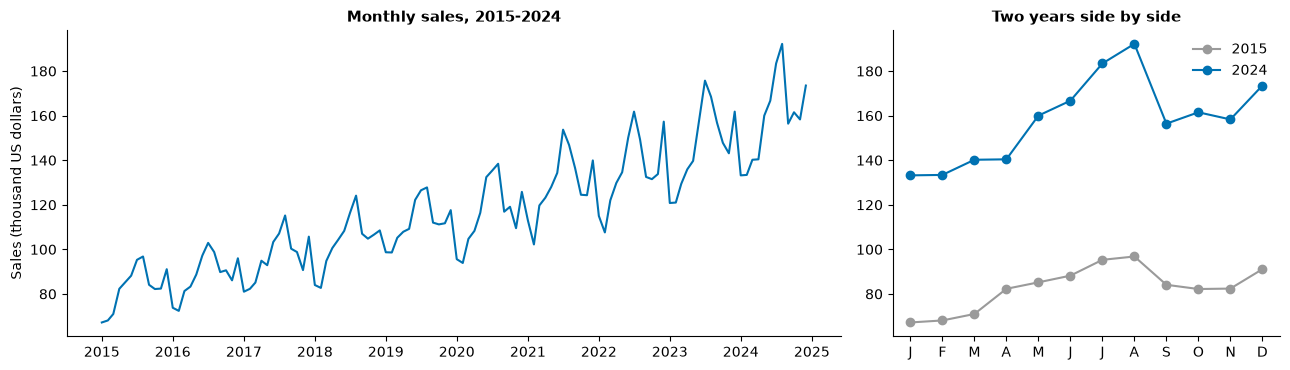

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(sales.index, sales, color=BLUE)
ax1.set_title("Monthly sales, 2015-2024")
ax1.set_ylabel("Sales (thousand US dollars)")

for year, colour in [(2015, GREY), (2024, BLUE)]:
    one = sales[str(year)]
    ax2.plot(one.index.month, one.values, marker="o", color=colour, label=str(year))
ax2.set_xticks(range(1, 13), list("JFMAMJJASOND"))
ax2.set_title("Two years side by side")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

The left chart shows an upward **trend** and a yearly **season**. The right chart shows the peak in July and August, a December bump, and a low in February. The **swing** is larger in 2024 than in 2015: the seasonal effect grows with the level of sales. That is **multiplicative** seasonality (summer is "about 15% above normal"), as opposed to **additive** seasonality (summer is "about 15 thousand dollars above normal"). The difference matters when we choose a model.

---

## Part 2: Decomposition (core: one chart; extension: the rest)

**Decomposition** separates a series into trend, seasonal and remainder parts:

- **Additive:** sales = trend + seasonal + remainder.
- **Multiplicative:** sales = trend × seasonal × remainder.

The classical method estimates the trend with a **centred 12-month moving average**, averages the detrended values for each calendar month to get the seasonal pattern, and calls whatever is left the remainder.

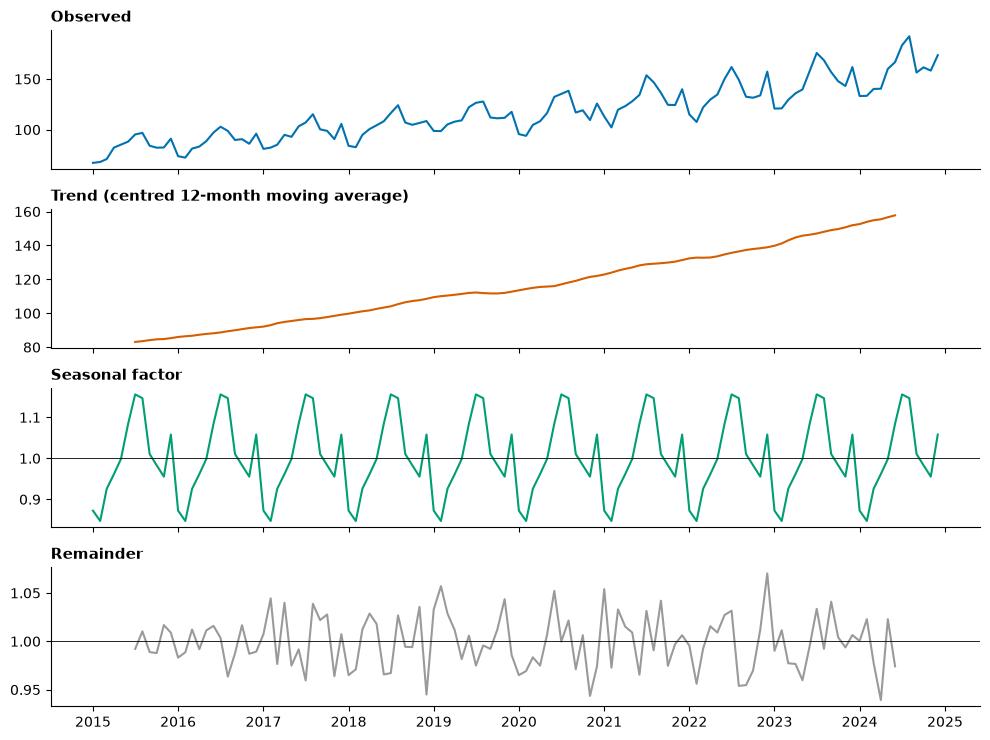

Seasonal factor by month (1.00 = an average month):
J    0.87
F    0.85
M    0.93
A    0.96
M    1.00
J    1.08
J    1.16
A    1.15
S    1.01
O    0.98
N    0.96
D    1.06


In [3]:
parts = seasonal_decompose(sales, model="multiplicative", period=12)

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, series, title, colour in zip(axes,
        [parts.observed, parts.trend, parts.seasonal, parts.resid],
        ["Observed", "Trend (centred 12-month moving average)", "Seasonal factor", "Remainder"],
        [BLUE, ORANGE, GREEN, GREY]):
    ax.plot(series.index, series, color=colour)
    ax.set_title(title, loc="left")
axes[2].axhline(1, color="black", lw=0.6)
axes[3].axhline(1, color="black", lw=0.6)
plt.tight_layout()
plt.show()

factors = parts.seasonal["2016"].values
print("Seasonal factor by month (1.00 = an average month):")
print(pd.Series(factors, index=list("JFMAMJJASOND")).round(2).to_string())

Read the seasonal factors as "July sales are typically about 16% above the trend; February about 15% below". Because we built this series ourselves, we can check: the factors are close to the `season` values used in the setup cell. On real data you never know the truth, which is why we test forecasts on held-out months.

Three cautions (extension):

1. The trend line is missing for the first and last six months: a **centred** average needs six months on each side. The most recent months, the ones a manager cares about most, are where decomposition is weakest.
2. Classical decomposition assumes the seasonal pattern is **the same every year**. Methods such as **STL** (`statsmodels.tsa.seasonal.STL`) let it change slowly.
3. Decomposition **describes** the past; it is not a forecast. But it tells you what a forecasting model must handle: here, a trend and a multiplicative season.

> **Misconception:** "Seasonality means anything that goes up and down." Seasonality has a **fixed, known period** (a year, a week, a day). Rises and falls of varying length, such as business cycles, are **cycles**, and they are far harder to forecast.

---

## Part 3: Train and test in time order (core)

A forecast is only worth something if it works on data the model has **not seen**. So we hide the most recent months (the **test** set, or holdout), fit on the rest (the **training** set), forecast the hidden months and compare.

Here we hold out the **last 24 months** (two full seasonal cycles), so every calendar month is tested twice.

Training: Jan 2015 to Dec 2022  (96 months)
Test:     Jan 2023 to Dec 2024  (24 months)


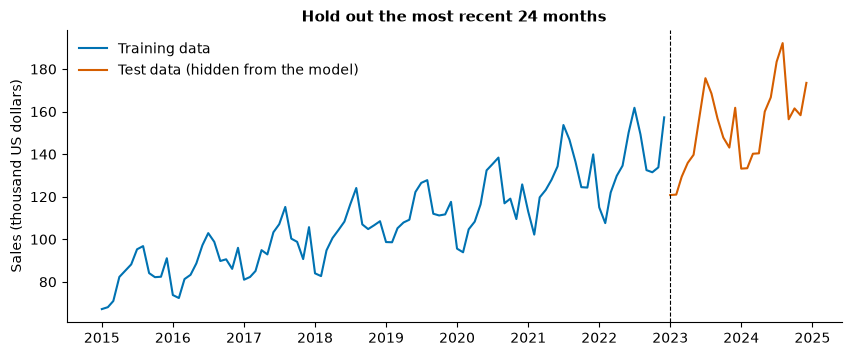

In [4]:
HORIZON = 24
train, test = sales.iloc[:-HORIZON], sales.iloc[-HORIZON:]
print(f"Training: {train.index[0]:%b %Y} to {train.index[-1]:%b %Y}  ({len(train)} months)")
print(f"Test:     {test.index[0]:%b %Y} to {test.index[-1]:%b %Y}  ({len(test)} months)")

fig, ax = plt.subplots()
ax.plot(train.index, train, color=BLUE, label="Training data")
ax.plot(test.index, test, color=ORANGE, label="Test data (hidden from the model)")
ax.axvline(test.index[0], color="black", lw=0.8, ls="--")
ax.set_ylabel("Sales (thousand US dollars)")
ax.set_title("Hold out the most recent 24 months")
ax.legend(frameon=False, loc="upper left")
plt.show()

### Why not a random split?

On Day 4 you will split rows **at random** into training and test sets. For a time series, that is a mistake.

> **Predict, then run.** Suppose we pick 20% of the months at random as the "test" set and "forecast" each one as the average of the month **before** and the month **after** it. Will the error be smaller or larger than an honest forecast of the last 24 months? Is that a fair test?

In [5]:
rng_split = np.random.default_rng(7)
test_positions = np.sort(rng_split.choice(np.arange(1, len(sales) - 1), size=24, replace=False))
neighbour_guess = (sales.values[test_positions - 1] + sales.values[test_positions + 1]) / 2
leaky_mae = np.mean(np.abs(sales.values[test_positions] - neighbour_guess))

honest_naive = np.full(HORIZON, train.iloc[-1])           # last known value, repeated
honest_mae = np.mean(np.abs(test.values - honest_naive))

print(f"Random split, 'forecast' from the months on either side:  MAE = {leaky_mae:5.1f}")
print(f"Time-ordered split, simplest honest forecast:            MAE = {honest_mae:5.1f}")

Random split, 'forecast' from the months on either side:  MAE =   5.8
Time-ordered split, simplest honest forecast:            MAE =  15.7


The random split looks far better, but it **cheated**: it used the month **after** each test month, which a real forecaster never has. A random split lets information from the future leak into training. The time-ordered split mimics real life: stand at a date, use only the past, forecast the future.

Rules for the split:

1. **Never shuffle.** Training data comes first, test data after.
2. Make the test period **at least as long as the horizon you will forecast**, and cover full seasonal cycles if the series is seasonal.
3. Use the test set **once**, at the end. If you try twenty models and keep the one with the best test score, the test set has become part of training (Part 10 shows a better way to compare).
4. After choosing the model, **refit it on all the data** before forecasting the real future.

---

## Part 4: Baselines and error measures (core)

### Error measures

For each test month, the **error** is actual − forecast. Three ways to summarise many errors:

| Measure | Formula | Units | Notes |
|---|---|---|---|
| **MAE** (mean absolute error) | mean of \|actual − forecast\| | Same as the data | "On average we are off by 7 thousand dollars." Easy to explain |
| **RMSE** (root mean squared error) | √(mean of (actual − forecast)²) | Same as the data | Squares first, so **large misses count more**. Always ≥ MAE |
| **MAPE** (mean absolute percentage error) | mean of \|actual − forecast\| ÷ \|actual\| × 100 | Percent | Lets you compare series of different sizes. Undefined when an actual is 0, and huge when actuals are near 0 |

> **Predict, then run.** Two forecasts for four months. Forecast A misses by 5 every month. Forecast B is perfect for three months and misses by 20 once. Which has the lower MAE? The lower RMSE?

In [6]:
def errors(actual, forecast):
    """MAE, RMSE and MAPE of a forecast."""
    e = np.asarray(actual) - np.asarray(forecast)
    return {"MAE": np.mean(np.abs(e)),
            "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE %": np.mean(np.abs(e) / np.abs(np.asarray(actual))) * 100}

actual_4 = [100, 120, 110, 130]
forecast_a = [105, 115, 115, 125]       # off by 5 every month
forecast_b = [100, 120, 110, 110]       # perfect, then one miss of 20
pd.DataFrame({"Forecast A": errors(actual_4, forecast_a),
              "Forecast B": errors(actual_4, forecast_b)}).round(2)

,Forecast A,Forecast B
MAE,5.00,5.00
RMSE,5.00,10.00
MAPE %,4.39,3.85


Same MAE, different RMSE: RMSE punishes the single big miss. Choose the measure that matches the **cost** of errors. If one large miss is a disaster (a stock-out at Christmas), watch RMSE. If cost grows in proportion to the size of the miss, MAE is the natural choice.

**Read every error against the scale of the series.** An MAE of 5 is tiny for sales of 5,000 and enormous for sales of 10. Report the MAE next to the average level, or report MAPE as well.

### Baselines

A **baseline** is a forecast so simple that any serious model must beat it. If it does not, the model is not worth its complexity.

| Baseline | Forecast for every future month | Good when |
|---|---|---|
| **Mean** | The average of all training data | The series has no trend or season (rare) |
| **Naive** | The last observed value | The series wanders (stock prices, exchange rates) |
| **Seasonal naive** | The value in the same month last year | A strong, stable season |

> **Predict, then run.** Which baseline will do best on the café test period? Which worst?

Average test-period sales: 152.4 thousand US dollars

                 MAE  RMSE  MAPE %
Mean            44.4  48.2    28.0
Naive           15.7  19.3    10.8
Seasonal naive  17.0  19.3    10.9


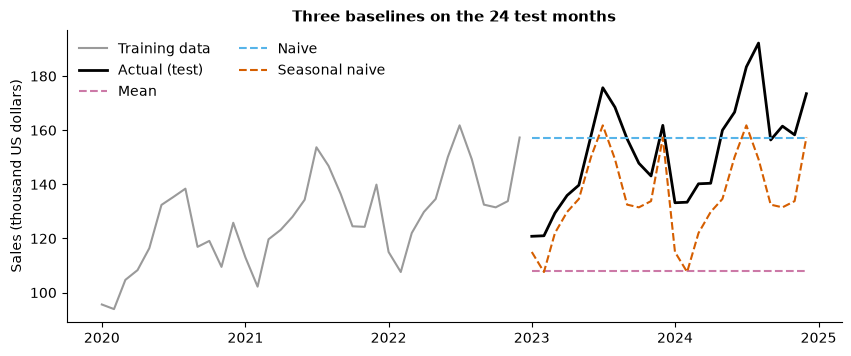

In [7]:
forecasts = {
    "Mean": pd.Series(train.mean(), index=test.index),
    "Naive": pd.Series(train.iloc[-1], index=test.index),
    "Seasonal naive": pd.Series(np.tile(train.iloc[-12:].values, HORIZON // 12), index=test.index),
}
scores = pd.DataFrame({name: errors(test, f) for name, f in forecasts.items()}).T
print("Average test-period sales:", round(test.mean(), 1), "thousand US dollars\n")
print(scores.round(1))

fig, ax = plt.subplots()
ax.plot(train["2020":].index, train["2020":], color=GREY, label="Training data")
ax.plot(test.index, test, color="black", lw=2, label="Actual (test)")
for (name, f), colour in zip(forecasts.items(), [PURPLE, SKY, ORANGE]):
    ax.plot(f.index, f, color=colour, ls="--", label=name)
ax.set_ylabel("Sales (thousand US dollars)")
ax.set_title("Three baselines on the 24 test months")
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

The mean is far too low: it averages ten years of a growing series. The naive forecast is flat, so it misses the season. The seasonal naive copies last year's shape but not the **growth** since then, so it is too low, more so in the second test year. Each baseline misses one component. That is the job of the models that follow: capture **level, trend and season** together. Keep these numbers; every model below must beat them.

---

## Part 5: Moving averages (core, short)

A **moving average** (MA) of order *k* averages the last *k* values. It has two uses that are easily confused:

- A **centred** MA smooths the past to **show the trend** (Part 2 used a centred 12-month MA). It needs future values, so it cannot forecast.
- A **trailing** MA averages the most recent *k* values and uses that as the **forecast** for the next period.

A trailing MA weights the *k* recent values equally and ignores the rest, so it **lags** behind any change. The clearest way to see the lag is a sudden step in demand:

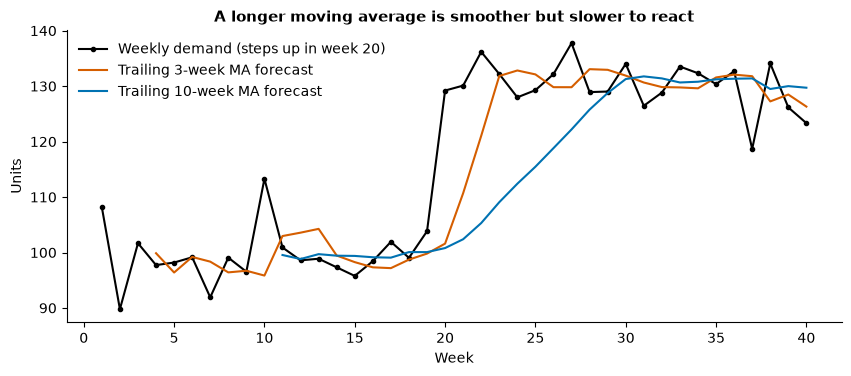

In [8]:
weeks = pd.RangeIndex(1, 41, name="week")
step_rng = np.random.default_rng(3)
demand = pd.Series(np.where(weeks < 20, 100, 130) + step_rng.normal(0, 4, 40), index=weeks)

fig, ax = plt.subplots()
ax.plot(weeks, demand, color="black", marker=".", label="Weekly demand (steps up in week 20)")
for k, colour in [(3, ORANGE), (10, BLUE)]:
    forecast_ma = demand.rolling(k).mean().shift(1)     # shift: use only weeks before the forecast week
    ax.plot(weeks, forecast_ma, color=colour, label=f"Trailing {k}-week MA forecast")
ax.set_xlabel("Week")
ax.set_ylabel("Units")
ax.set_title("A longer moving average is smoother but slower to react")
ax.legend(frameon=False, loc="upper left")
plt.show()

The 3-week MA catches up within three weeks but wobbles with the noise; the 10-week MA is smooth but takes ten weeks to catch up. **Every smoother trades responsiveness for stability.** Note the `.shift(1)`: without it, each week's "forecast" would include that week's own value, a small version of the leak in Part 3.

On the café series a trailing 12-month MA forecasts a flat line at last year's average: no trend, no season. It is a smoother, not a full forecasting model.

---

## Part 6: Exponential smoothing (extension)

**Simple exponential smoothing (SES)** forecasts with a weighted average of **all** past values, with weights that shrink geometrically into the past:

> **next forecast = α × latest actual + (1 − α) × latest forecast**, with α between 0 and 1.

Unrolled, the weight on the value *j* periods ago is α × (1 − α)<sup>j</sup>:

In [9]:
weights = pd.DataFrame({f"alpha = {a}": [a * (1 - a) ** j for j in range(6)] for a in [0.2, 0.5, 0.8]},
                       index=[f"{j} periods ago" for j in range(6)])
weights.round(3)

,alpha = 0.2,alpha = 0.5,alpha = 0.8
0 periods ago,0.200,0.500,0.800
1 periods ago,0.160,0.250,0.160
2 periods ago,0.128,0.125,0.032
3 periods ago,0.102,0.062,0.006
4 periods ago,0.082,0.031,0.001
5 periods ago,0.066,0.016,0.000


A large α trusts the latest value (fast, but jumpy); a small α remembers a long history (smooth, but slow). statsmodels chooses α by minimising the one-step-ahead errors on the training data.

SES has only a **level**, so its forecast is flat. Two extensions add the missing components:

| Method | Components | Parameters | Forecast shape |
|---|---|---|---|
| **Simple** (SES) | Level | α | Flat |
| **Holt** (linear trend) | Level + trend | α, β | Straight line |
| **Holt-Winters** | Level + trend + season (additive or multiplicative) | α, β, γ | Line with the seasonal pattern |

> **Predict, then run.** Which of the three will beat the seasonal naive baseline on the café test period?

                                       MAE  RMSE  MAPE %
Mean                                  44.4  48.2    28.0
Naive                                 15.7  19.3    10.8
Seasonal naive                        17.0  19.3    10.9
SES                                   15.6  19.1    10.8
Holt                                  19.1  22.0    13.5
Holt-Winters (additive season)         7.9  10.0     4.8
Holt-Winters (multiplicative season)   6.9   8.4     4.4


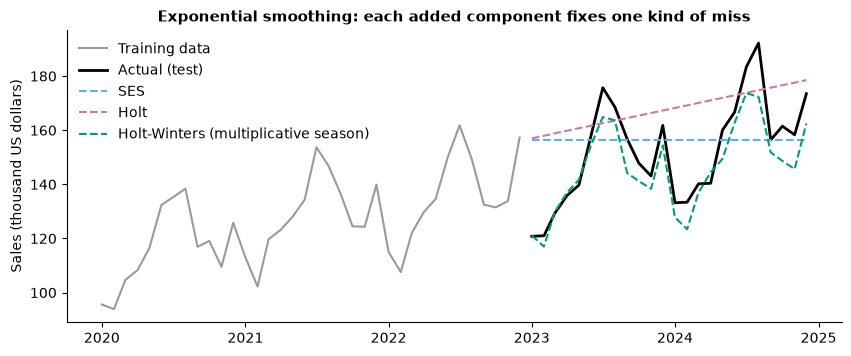

In [10]:
smoothers = {
    "SES": SimpleExpSmoothing(train, initialization_method="estimated").fit(),
    "Holt": ExponentialSmoothing(train, trend="add", initialization_method="estimated").fit(),
    "Holt-Winters (additive season)": ExponentialSmoothing(
        train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(),
    "Holt-Winters (multiplicative season)": ExponentialSmoothing(
        train, trend="add", seasonal="mul", seasonal_periods=12, initialization_method="estimated").fit(),
}
for name, fit in smoothers.items():
    forecasts[name] = fit.forecast(HORIZON)
scores = pd.DataFrame({name: errors(test, f) for name, f in forecasts.items()}).T
print(scores.round(1))

fig, ax = plt.subplots()
ax.plot(train["2020":].index, train["2020":], color=GREY, label="Training data")
ax.plot(test.index, test, color="black", lw=2, label="Actual (test)")
for name, colour in [("SES", SKY), ("Holt", PURPLE), ("Holt-Winters (multiplicative season)", GREEN)]:
    ax.plot(test.index, forecasts[name], color=colour, ls="--", label=name)
ax.set_ylabel("Sales (thousand US dollars)")
ax.set_title("Exponential smoothing: each added component fixes one kind of miss")
ax.legend(frameon=False, loc="upper left")
plt.show()

SES is flat like the naive forecast. Holt adds the trend but no season, and here it does **worse** than the naive forecast: a straight line drawn through the seasonal ups and downs misses badly at the peaks and troughs. Adding one component without the other can hurt. Holt-Winters captures both, and the **multiplicative** version, which matches the growing swings we saw in Part 1, does best of the smoothers. The lesson is not "Holt-Winters always wins"; it is "**match the model's components to the components in the data**", which is why we plot and decompose first. Excel's **Forecast Sheet** (Day 6) uses an additive Holt-Winters method (ETS AAA).

---

## Part 7: Stationarity, the ADF test and differencing (core)

A series is **stationary** if its statistical behaviour does not change over time: constant mean, constant variance, and the same relationship between neighbours. ARIMA models assume stationarity (after any differencing), because they learn "how this month relates to last month" and use that rule forever.

> **Predict, then run.** Three simulated series follow. Which are stationary: white noise (independent random values), a random walk (each value = previous value + random step), or a trend plus noise?

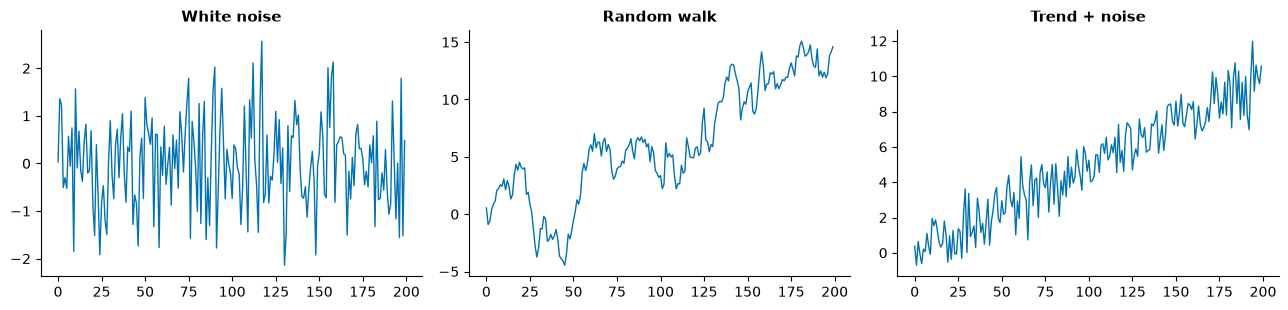

In [11]:
sim_rng = np.random.default_rng(11)
n = 200
white_noise = pd.Series(sim_rng.normal(0, 1, n))
random_walk = pd.Series(sim_rng.normal(0, 1, n)).cumsum()
trend_noise = pd.Series(0.05 * np.arange(n) + sim_rng.normal(0, 1, n))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, s, title in zip(axes, [white_noise, random_walk, trend_noise],
                        ["White noise", "Random walk", "Trend + noise"]):
    ax.plot(s, color=BLUE, lw=1)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Only white noise is stationary: it keeps returning to the same mean with the same spread. The trend has a mean that changes. The random walk is the subtle case: it has no trend built in, yet it wanders without ever returning, and its spread grows with time. Many business and financial series behave like random walks.

### The Augmented Dickey-Fuller (ADF) test

| | |
|---|---|
| **Null hypothesis** | The series has a **unit root**: it is **not** stationary (it behaves like a random walk) |
| **Small p-value (≤ 0.05)** | Reject the null: evidence the series **is** stationary |
| **Large p-value (> 0.05)** | Cannot reject: treat the series as **not** stationary, and difference it |

This is the reverse of many tests you know: here the **small** p-value is the "good" result. `adfuller(series)` returns the test statistic first and the p-value second.

In [12]:
def adf_report(series, label):
    stat, p = adfuller(series.dropna())[:2]
    verdict = "stationary" if p <= 0.05 else "not stationary"
    print(f"{label:<16} ADF statistic = {stat:7.2f}   p-value = {p:.3f}   -> {verdict}")

adf_report(white_noise, "White noise")
adf_report(random_walk, "Random walk")
adf_report(trend_noise, "Trend + noise")

White noise      ADF statistic =  -14.09   p-value = 0.000   -> stationary
Random walk      ADF statistic =   -1.12   p-value = 0.706   -> not stationary
Trend + noise    ADF statistic =   -0.45   p-value = 0.901   -> not stationary


A caution on the trend series: `adfuller` by default allows for a constant but not a trend, so a steady trend reads as non-stationary. (With `regression="ct"` it tests "stationary around a trend" instead.) Know which question your test asks.

### Differencing

**First differencing** replaces each value with its change from the previous one: this month minus last month. It removes a trend and turns a random walk into white noise. **Seasonal differencing** subtracts the value one season ago: this month minus the same month last year, for monthly data. It removes a stable seasonal pattern.

> **Predict, then run.** The café training data has a trend and a season. Which of these will the ADF test call stationary: the level, the first difference, the seasonal difference?

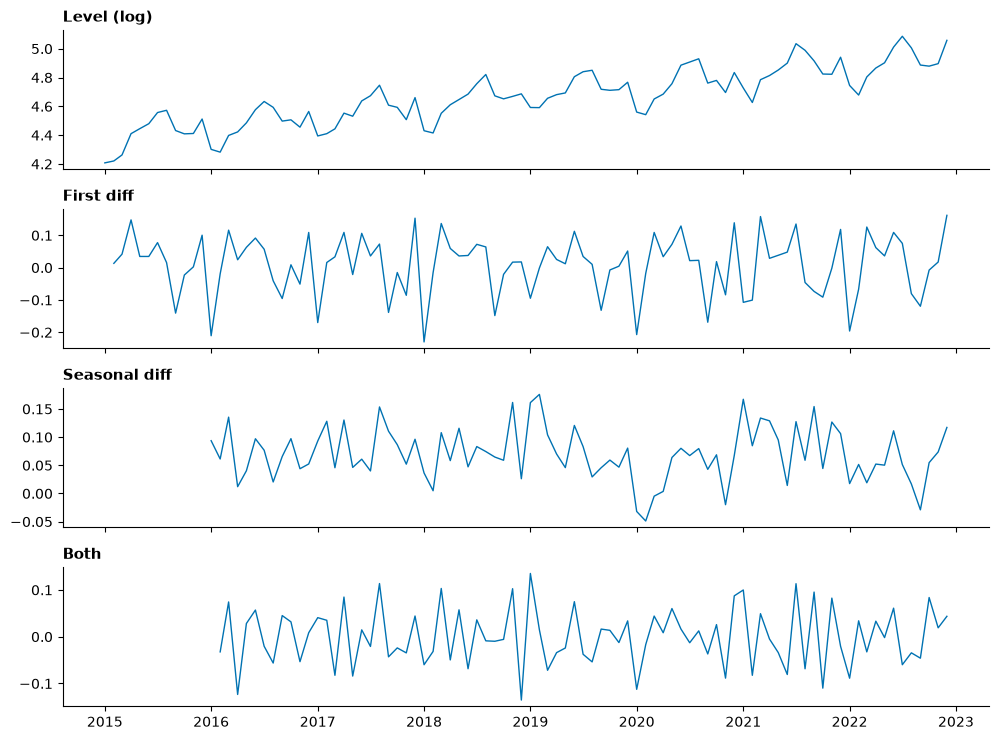

Level (log)      ADF statistic =   -0.58   p-value = 0.875   -> not stationary
First diff       ADF statistic =  -15.62   p-value = 0.000   -> stationary
Seasonal diff    ADF statistic =   -5.07   p-value = 0.000   -> stationary
Both             ADF statistic =   -2.77   p-value = 0.063   -> not stationary


In [13]:
log_train = np.log(train)     # logs turn multiplicative growth and seasonality into additive
versions = {
    "Level (log)": log_train,
    "First diff": log_train.diff(),
    "Seasonal diff": log_train.diff(12),
    "Both": log_train.diff().diff(12),
}
fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, (label, s) in zip(axes, versions.items()):
    ax.plot(s.index, s, color=BLUE, lw=1)
    ax.set_title(label, loc="left")
plt.tight_layout()
plt.show()

for label, s in versions.items():
    adf_report(s, label)

Read the charts and the p-values together:

- The **level** trends upward: not stationary.
- The **first difference** has no trend, and the ADF test calls it stationary, yet the chart still shows a strong **repeating pattern**. The ADF test checks for a unit root, **not** for seasonality. Never read a test without the chart.
- The **seasonal difference** removes the season (it is the growth rate compared with the same month last year).
- **Both** differences together: no trend, no season, a series that fluctuates around zero. Its ADF p-value may land near 0.05; with short series, tests have limited power, which is one more reason to look at the chart.

We took **logs** first: with multiplicative seasonality, logs turn "15% above normal" into a constant **additive** shift, and differences of logs are approximately **percentage changes**.

> **Misconception:** "Difference until the p-value is tiny." Each difference throws information away and adds noise. Use the fewest differences that remove the trend and the season: usually *d* = 1, plus *D* = 1 for a strong season.

---

## Part 8: ARIMA and SARIMA (core: orders; extension: ACF)

**ARIMA(p, d, q)** combines three ideas, applied to the differenced series:

| Letter | Name | Meaning | Intuition |
|---|---|---|---|
| **p** | AutoRegressive order | Uses the last *p* **values** | "This month is like last month" |
| **d** | Integrated (differencing) order | Differences taken | Removes the trend |
| **q** | Moving-Average order | Uses the last *q* **forecast errors** | "Correct for last month's surprise" (not the same as Part 5's moving average) |

**SARIMA(p, d, q)(P, D, Q)ₛ** adds the same three ideas at the **seasonal lag** *s* (12 for monthly data): *P* seasonal AR terms (this July is like last July), *D* seasonal differences, *Q* seasonal MA terms. Examples:

| Model | Reads as |
|---|---|
| ARIMA(0, 1, 0) | The random walk: the naive forecast |
| ARIMA(0, 1, 1) | Equivalent to simple exponential smoothing |
| SARIMA(0, 1, 1)(0, 1, 1)₁₂ | One ordinary and one seasonal difference, one MA term at each level: the classic "airline model" for monthly series with trend and season |
| SARIMA(1, 1, 0)(1, 1, 0)₁₂ | Same differences, AR terms instead of MA terms |

How are *p*, *q*, *P*, *Q* chosen? Two common ways: read the **autocorrelation plots** (extension below), or try a few small orders and keep the one with the lowest **AIC** (an in-sample score that penalises extra parameters). Keep orders small (0, 1 or 2); large orders overfit.

Here we fit the airline model to the **log** of the training data and transform the forecast back.

In [14]:
sarima = sm.tsa.statespace.SARIMAX(np.log(train), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
sarima_fc = sarima.get_forecast(steps=HORIZON)
forecasts["SARIMA(0,1,1)(0,1,1)12 on logs"] = np.exp(sarima_fc.predicted_mean)

scores = pd.DataFrame({name: errors(test, f) for name, f in forecasts.items()}).T.sort_values("RMSE")
print(f"Average test-period sales: {test.mean():.1f} thousand US dollars\n")
print(scores.round(1))

Average test-period sales: 152.4 thousand US dollars

                                       MAE  RMSE  MAPE %
SARIMA(0,1,1)(0,1,1)12 on logs         3.8   4.8     2.5
Holt-Winters (multiplicative season)   6.9   8.4     4.4
Holt-Winters (additive season)         7.9  10.0     4.8
SES                                   15.6  19.1    10.8
Seasonal naive                        17.0  19.3    10.9
Naive                                 15.7  19.3    10.8
Holt                                  19.1  22.0    13.5
Mean                                  44.4  48.2    28.0


Read the table from the top: the models that capture level, trend **and** multiplicative season beat every baseline, and the best are a few percent off on average (see MAPE). Because our series was **built** with a trend and a multiplicative season, it is no surprise that the matching models win. On real data the ranking is less predictable, and the gap between models is often smaller than the gap between a model and a naive baseline.

> **Check your understanding.** (1) A colleague fits ARIMA(2, 0, 1) to monthly sales that grow every year. What is wrong with *d* = 0? (2) Which SARIMA order is the same as "the seasonal naive forecast"? (Hint: one seasonal difference and nothing else.)

### Extension: reading autocorrelation plots

The **ACF** (autocorrelation function) shows the correlation of a series with itself 1, 2, 3, … periods earlier. The **PACF** shows the same after removing the effect of the shorter lags. On the differenced series, rough rules: a sharp cut-off in the PACF after lag *p* suggests AR(*p*); a sharp cut-off in the ACF after lag *q* suggests MA(*q*); spikes at lag 12 point to seasonal terms.

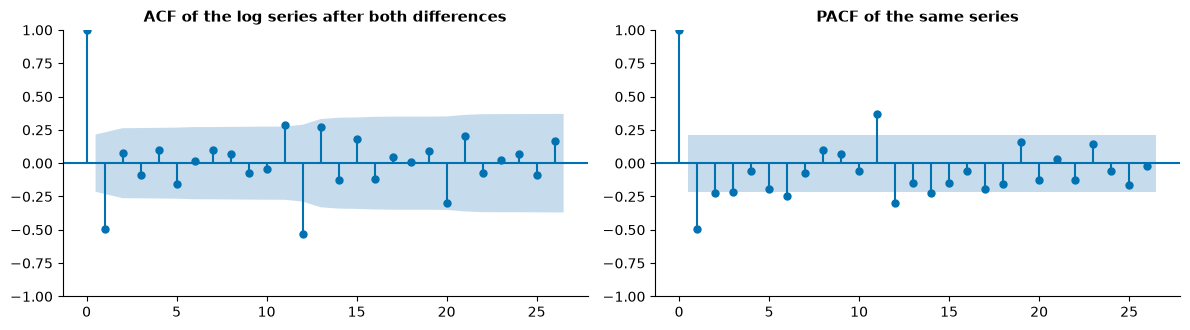

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

stationary = np.log(train).diff().diff(12).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
plot_acf(stationary, lags=26, ax=axes[0], color=BLUE, vlines_kwargs={"colors": BLUE})
plot_pacf(stationary, lags=26, ax=axes[1], method="ywm", color=BLUE, vlines_kwargs={"colors": BLUE})
axes[0].set_title("ACF of the log series after both differences")
axes[1].set_title("PACF of the same series")
plt.tight_layout()
plt.show()

The large negative spike at lag 1 in the ACF, and another near lag 12, are the signature of the airline model: one MA term and one seasonal MA term. Differencing a series that has noise tends to create exactly this negative lag-1 correlation. The shaded band is roughly the 95% range for "no correlation"; bars inside it are noise.

---

## Part 9: Forecast intervals (core)

A point forecast says "sales next July will be 200". It will almost certainly be wrong by something. A **forecast interval** says how wrong it could plausibly be: "an 80% interval of 190 to 210" means that, if the model's assumptions hold, about 8 out of 10 such intervals contain the actual value.

> **Predict, then run.** Will the interval be the same width for every month of the 24-month test period?

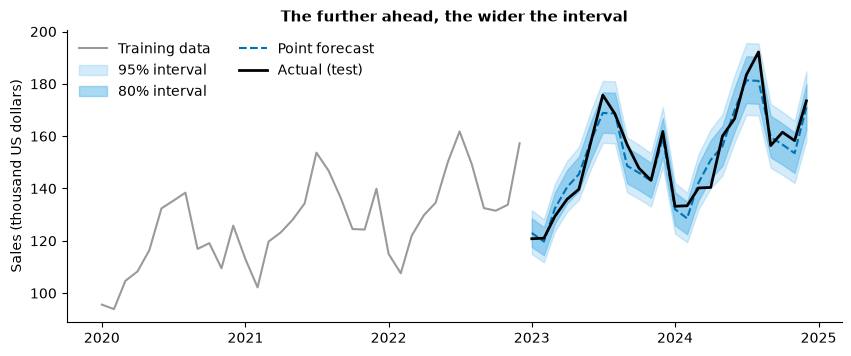

95% interval width, first test month: 16.7;  last test month: 26.5
Share of test months inside the 80% interval: 88%
Share of test months inside the 95% interval: 100%


In [16]:
ci95 = np.exp(sarima_fc.conf_int(alpha=0.05))
ci80 = np.exp(sarima_fc.conf_int(alpha=0.20))
point = forecasts["SARIMA(0,1,1)(0,1,1)12 on logs"]

fig, ax = plt.subplots()
ax.plot(train["2020":].index, train["2020":], color=GREY, label="Training data")
ax.fill_between(test.index, ci95.iloc[:, 0], ci95.iloc[:, 1], color=SKY, alpha=0.25, label="95% interval")
ax.fill_between(test.index, ci80.iloc[:, 0], ci80.iloc[:, 1], color=SKY, alpha=0.5, label="80% interval")
ax.plot(test.index, point, color=BLUE, ls="--", label="Point forecast")
ax.plot(test.index, test, color="black", lw=2, label="Actual (test)")
ax.set_ylabel("Sales (thousand US dollars)")
ax.set_title("The further ahead, the wider the interval")
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

width = ci95.iloc[:, 1] - ci95.iloc[:, 0]
print(f"95% interval width, first test month: {width.iloc[0]:.1f};  last test month: {width.iloc[-1]:.1f}")
for name, ci in [("80%", ci80), ("95%", ci95)]:
    inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).mean()
    print(f"Share of test months inside the {name} interval: {inside:.0%}")

Two lessons:

1. **Intervals widen with the horizon.** Each month ahead adds a new unknown shock on top of the earlier ones. A forecast for next month is much more certain than one for two years out. (On the log scale the interval is symmetric; back on the dollar scale it is wider above than below.)
2. **Check the coverage.** If the 80% interval contains the actual value in about 80% of test months, the intervals are honest. Ours contain it at least as often as promised; with only 24 months to check, that is as close as we can judge. On real data intervals are often **too narrow**: they assume the model is right and the future behaves like the past, and they ignore surprises such as a pandemic, a new competitor or a price change.

> **Misconception:** "A 95% interval means there is a 95% chance the model is right." It describes the **noise the model knows about**. It does not cover the model being the wrong model, or the world changing.

---

## Part 10: Choosing a model: rolling-origin evaluation (extension)

One test period is one draw of luck. A sturdier comparison repeats the test from several **origins**: stand at the end of 2020, forecast 2021; stand at the end of 2021, forecast 2022; and so on, always training only on data before the origin. This is **rolling-origin** (or time-series cross-validation) evaluation.

In [17]:
def fit_and_forecast(name, history, h=12):
    if name == "Seasonal naive":
        return np.tile(history.iloc[-12:].values, h // 12)
    if name == "Holt-Winters (mult.)":
        return ExponentialSmoothing(history, trend="add", seasonal="mul", seasonal_periods=12,
                                    initialization_method="estimated").fit().forecast(h).values
    fit = sm.tsa.statespace.SARIMAX(np.log(history), order=(0, 1, 1),
                                    seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return np.exp(fit.forecast(h)).values

rows = []
for origin_year in [2019, 2020, 2021, 2022, 2023]:
    history = sales[:str(origin_year)]
    actual = sales[str(origin_year + 1)]
    for name in ["Seasonal naive", "Holt-Winters (mult.)", "SARIMA airline (logs)"]:
        rows.append({"forecast year": origin_year + 1, "model": name,
                     "MAPE %": errors(actual, fit_and_forecast(name, history))["MAPE %"]})
backtest = pd.DataFrame(rows).pivot(index="forecast year", columns="model", values="MAPE %")
print(backtest.round(1))
print("\nAverage over the five years:")
print(backtest.mean().round(1).sort_values().to_string())

model          Holt-Winters (mult.)  SARIMA airline (logs)  Seasonal naive
forecast year                                                             
2020                            3.2                    4.7             4.7
2021                            3.8                    3.6             9.7
2022                            2.9                    3.5             5.2
2023                            3.2                    2.1             7.5
2024                            3.1                    2.7             7.4

Average over the five years:
model
Holt-Winters (mult.)     3.2
SARIMA airline (logs)    3.3
Seasonal naive           6.9


The ranking is more trustworthy because it rests on five years, not one, and you can see how much each model's error varies from year to year. Choose the model with a good **and stable** error, prefer the simpler one when the difference is small, and then refit it on **all** the data to forecast the real future.

---

## Part 11: Communicating uncertainty for a decision (core summary, extension detail)

A forecast is an input to a decision: how many staff to roster, how much coffee to order, what budget to set. Five rules for presenting one:

1. **Give a range, not just a number.** "July sales: about 197 thousand dollars, likely between 189 and 206 (80% interval)."
2. **Say how good the method has been**, in the reader's units: "Over the last five years, this method's monthly forecasts were off by about 3% on average."
3. **State the assumptions**: "Assumes no new branches, no price change, and a normal summer."
4. **Show it as a fan chart** (as in Part 9), with the history for context, actual and forecast clearly distinguished, and the horizon labelled.
5. **Connect the range to the cost of being wrong.** If running out costs more than over-ordering, plan to a **high** point of the range, not the middle.

Here is rule 5 in action. We refit the airline model on **all ten years** and forecast 2025. For a summer stock order where a shortfall is three times as costly as a surplus, the right quantity is not the point forecast but a higher **quantile**: the level that demand stays below 75% of the time (because 3 ÷ (3 + 1) = 0.75; this is the "newsvendor" rule).

In [18]:
from scipy.stats import norm

final = sm.tsa.statespace.SARIMAX(np.log(sales), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
future = final.get_forecast(steps=12)
mean_log = future.predicted_mean
sd_log = future.se_mean

plan = pd.DataFrame({
    "point forecast": np.exp(mean_log),
    "80% low": np.exp(mean_log + norm.ppf(0.10) * sd_log),
    "80% high": np.exp(mean_log + norm.ppf(0.90) * sd_log),
    "plan to (75th percentile)": np.exp(mean_log + norm.ppf(0.75) * sd_log),
}).round(1)
plan.index = plan.index.strftime("%b %Y")
plan.loc[["Jun 2025", "Jul 2025", "Aug 2025"]]

,point forecast,80% low,80% high,plan to (75th percentile)
Jun 2025,183.2,175.4,191.3,187.4
Jul 2025,197.0,188.6,205.7,201.5
Aug 2025,197.2,188.8,206.0,201.8


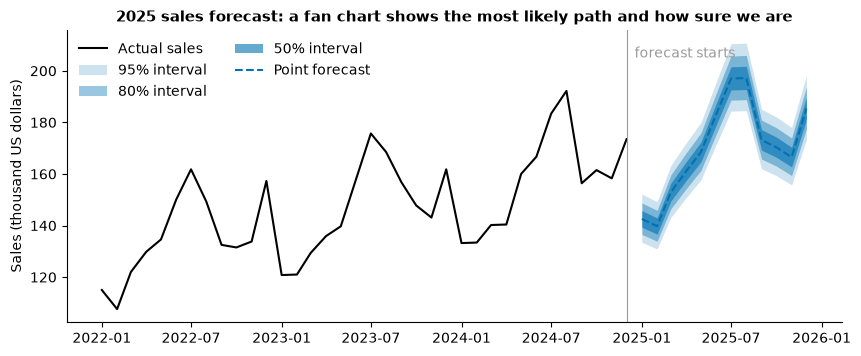

In [19]:
fig, ax = plt.subplots()
ax.plot(sales["2022":].index, sales["2022":], color="black", label="Actual sales")
for level, alpha in [(0.95, 0.2), (0.80, 0.4), (0.50, 0.6)]:
    ci = np.exp(future.conf_int(alpha=1 - level))
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color=BLUE, alpha=alpha, lw=0,
                    label=f"{level:.0%} interval")
ax.plot(mean_log.index, np.exp(mean_log), color=BLUE, ls="--", label="Point forecast")
ax.axvline(sales.index[-1], color=GREY, lw=0.8)
ax.text(sales.index[-1], ax.get_ylim()[1] * 0.97, "  forecast starts", color=GREY, va="top")
ax.set_ylabel("Sales (thousand US dollars)")
ax.set_title("2025 sales forecast: a fan chart shows the most likely path and how sure we are")
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

Words matter as much as the chart. Compare:

| Weak | Better |
|---|---|
| "July sales will be 197." | "July sales will most likely be about 197 thousand dollars; 8 times in 10 they should fall between 189 and 206." |
| "The model is 97% accurate." | "In tests on each of the last five years, monthly forecasts were off by about 3% on average, and by under 5% in the worst year." |
| "Sales will grow 7%." | "If the past trend continues and nothing structural changes, sales will grow about 7%." |

Gordon's Chapter 9, as summarised in the reading packet, adds a caution: forecasts are weakest when a disruption breaks the pattern, and analysts may need to set aside or adjust unusual periods rather than extend them mechanically. A model fitted to 2015–2019 knew nothing of 2020.

> **Misconception:** "A more complex model gives a more certain forecast." Complexity can fit the past better without making the future more knowable. The interval width comes from how noisy the series is and how far ahead you look.

---

## Part 12: Business case (extension)

**A city hospital** forecasts daily emergency-department arrivals to set nurse rosters four weeks ahead. Its current method is "same day last year". An analyst proposes a SARIMA model with weekly seasonality and reports a test-period MAPE of 6%, against 11% for the current method.

Discuss in groups:

1. Daily data has a 7-day season **and** a yearly season, plus holidays. What would *s* be in a SARIMA model, and what would it miss?
2. Which costs more for the hospital: under-forecasting or over-forecasting arrivals? So which point of the forecast range should the roster use?
3. The test period was a calm autumn. What other test would you ask for before switching methods?
4. During an epidemic, arrivals double for six weeks. Should those weeks be used to train next year's model? What are the options (keep, remove, model them as a separate effect)?
5. Write the two sentences you would put on the roster planner's dashboard to explain the forecast and its uncertainty.

---

## Part 13: Lab 4 briefing (core)

In Lab 4 (periods 7 and 8) you forecast monthly atmospheric CO₂ from the Mauna Loa record that ships with statsmodels. You resample weekly readings to monthly, plot the series, run an ADF test, split the data **in time order** (GAP's split, not the 24-month holdout used here), fit a SARIMA model with the orders GAP gives, forecast the test period, compute RMSE and MAE, plot actual against forecast, and answer questions.

| Lab step | Lecture part to revisit |
|---|---|
| Resampling weekly data to monthly | The [Lab 4 guide](guides/lab4_forecasting.md), pitfalls (`"ME"` and pandas versions) |
| Reading the plot: trend and season | Parts 1 and 2 |
| ADF test: null hypothesis, reading the p-value, why *d* = 1 | Part 7 |
| Sequential train/test split and why it matters | Part 3 |
| SARIMA orders | Part 8 |
| RMSE and MAE, judged against the scale of the series | Part 4 |
| Did the forecast follow the trend and the seasonal zig-zag? | Parts 8 and 9 |

Read every value **from your own output**, give units (ppm), and compare errors with the size of the series. The SARIMA fit takes a little while, especially in Try JupyterLab: run it once and wait.

---

## Part 14: Practice, quiz and summary

### Practice

#### Core

**Core 1.** Change `HORIZON` to 12 and re-run Parts 3 and 4. Do the baselines keep the same ranking? Why might the seasonal naive do better over one year than over two?

**Core 2.** For the café test period, compute the MAE of the seasonal naive forecast **by hand** for the first three test months, using the printed values (`test.head(3)` and `forecasts["Seasonal naive"].head(3)`). Check it against `errors()`.

**Core 3.** Write two sentences for the café's finance director that give the July 2025 forecast with its 80% interval and one assumption.

#### Stretch

**Stretch 1.** Fit SARIMA(1,1,0)(1,1,0)₁₂ on the log training data and compare its test errors and AIC (`fit.aic`) with the airline model. Which would you choose, and why?

**Stretch 2.** Add a "seasonal naive with drift" baseline: last year's value for the month, times the growth between the last two years. Does it beat Holt-Winters?

**Stretch 3.** In the step-demand example, add an SES forecast with α = 0.2 and α = 0.8. Which reacts like the 3-week MA, and which like the 10-week MA?

#### Challenge

**Challenge 1.** Load the annual Nile river flow, `sm.datasets.nile.load_pandas().data`, which ships with statsmodels. Plot it, run the ADF test, and fit ARIMA(0,1,1). Forecast ten years ahead with an interval. The series has a known drop around 1898: does the model's interval account for a break like that?

**Challenge 2.** Rerun the rolling-origin backtest with RMSE instead of MAPE, and with 6-month instead of 12-month horizons. Does the ranking change?

**Challenge 3.** Simulate 200 series like the café data with different seeds, fit the airline model to each training set, and record how often the 80% interval for the first test month contains the actual value. Is the coverage close to 80%?

### Quiz

1. Give two reasons why a time series cannot be split at random into training and test sets.
2. Name the four components of a time series and give a business example of each.
3. What is the difference between additive and multiplicative seasonality? How can you tell them apart on a chart?
4. Define the naive and seasonal naive forecasts. Why compare every model with them?
5. MAE = 4 and RMSE = 9 for one forecast. What does the gap tell you?
6. When should you not use MAPE?
7. In exponential smoothing, what does a large α do?
8. State the null hypothesis of the ADF test. Is a p-value of 0.40 good or bad news for fitting ARIMA without differencing?
9. What does *d* = 1 do? What does *D* = 1 with *s* = 12 do?
10. Read SARIMA(0,1,1)(0,1,1)₁₂ aloud in words.
11. Why does a forecast interval widen with the horizon? What does it not account for?
12. A shortfall costs four times as much as a surplus. Which percentile of the forecast should you plan to?

### Summary

| Idea | Remember |
|---|---|
| Time series | Order matters; neighbours are correlated |
| Components | Trend, seasonality (fixed period), cycle (varying), noise; additive or multiplicative |
| Decomposition | Centred MA trend + monthly factors + remainder; weakest at the ends |
| Split | In time order; test ≥ horizon and full seasons; use the test set once; refit on all data |
| Errors | MAE (typical miss), RMSE (punishes big misses), MAPE (percent; not near zero); always against the scale |
| Baselines | Mean, naive, seasonal naive; every model must beat them |
| Smoothing | MA lags; SES level; Holt + trend; Holt-Winters + season; α trades speed for stability |
| Stationarity | ADF null = not stationary; small p = stationary; ADF does not detect seasonality; difference sparingly |
| SARIMA | (p, d, q)(P, D, Q)ₛ: AR, differencing, MA, and the same at the seasonal lag; keep orders small |
| Intervals | Widen with horizon; check coverage; do not cover structural change |
| Communicating | Range plus track record plus assumptions; plan to the quantile that matches the cost of errors |

**References:** Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5th ed.). Wiley. Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, 74(366), 427–431. Holt, C. C. (1957/2004). Forecasting seasonals and trends by exponentially weighted moving averages. *International Journal of Forecasting*, 20(1), 5–10. Winters, P. R. (1960). Forecasting sales by exponentially weighted moving averages. *Management Science*, 6(3), 324–342. Gordon, M. E. (2023). *Business analytics*, Chapter 9. SAGE.

**Next:** the [Lab 3 guide](guides/lab3_text_mining.md) and the [Lab 4 guide](guides/lab4_forecasting.md). Earlier: [Text mining](D3_lecture_text_mining.md).

---

## For the facilitator

This notebook is the **core path for period P4** of Day 3. Text mining was P3; Lab 3 follows in P5–P6 and Lab 4 in P7–P8. One period cannot hold all of forecasting, so the parts are marked **core** and **extension**: teach the core in P4, and use the extensions in a later study block (Part 6 pairs well with Day 6 P3, Excel's Forecast Sheet), with faster students during Lab 4, or as self-study. No Lab 4 answers are given: the CO₂ series is never loaded, and the split and models differ from the lab's.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P4 | 5 | Setup; Part 1: components, the two-year chart | Take the peak-month prediction first |
| P4 | 3 | Part 2: the decomposition chart only | One sentence on multiplicative vs additive |
| P4 | 7 | Part 3: time-ordered split and the random-split leak | Ask for the prediction; stress "the month after" |
| P4 | 9 | Part 4: MAE, RMSE, MAPE (A vs B) and the three baselines | Students compute A and B by hand first |
| P4 | 3 | Part 5: the step-demand chart | "Every smoother trades speed for stability" |
| P4 | 9 | Part 7: stationarity, ADF null, differencing | Spend time on "small p-value = stationary" and on the first-difference chart |
| P4 | 5 | Part 8: SARIMA orders table and the score table | Skip the ACF |
| P4 | 4 | Part 9 (fan chart, widening) and Part 13 (Lab 4 briefing) | Remind students the SARIMA fit takes time |
| Later | 20 | Extensions: Part 6 (exponential smoothing) | Link to Excel's Forecast Sheet on Day 6 |
| Later | 25 | Extensions: Part 8 ACF, Part 10 backtest, Part 11 newsvendor plan | Good for the online week |
| Later | 15 | Part 12 business case | Group discussion |
| Self-study | — | Part 14: practice and quiz | Core items first |

If time is short, show Part 4's baseline chart without the table, and go straight from the ADF table to the SARIMA order table.